<a href="https://colab.research.google.com/github/ivorywang-1005/intro-to-urban-data/blob/main/Scale/S09_Scale_Calling_an_API.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **09 Scale**  Calling an API to get external data

```
    Class       ARCH 6131 Urban Design Methods / Skills / Tools 1
                Tata Innovation Center
                Fall 2025
                Monday 9:30 AM to 12 PM

    Instructor  Brian Ho
                brian@brian-ho.io
```

This notebook is a quick demonstration of how you can call an external Application Programming Interface (API) to fetch data from providers and live sources, rather than just downloading existing files.

If you'd like to incoporate an API into your coursework, let me know! There are some nuanced to setting them up that we can review together.

## About APIs
APIs are made available by a variety of public and private sources, either for free or as a paid offering. One example that we'll use in this notebook are APIs from HERE (https://developer.here.com/) a company that provides geospatial information. Other APIs you might explore include:
- Google Maps Platform (https://mapsplatform.google.com/)
- Mapbox (https://www.mapbox.com/)
- Mapillary (https://www.mapillary.com/developer)

... and more! The internet is truly your oyster — being able to call APIs enables you to access a number of "developer" tools. Of course, that comes with the caveat that things get a little tricker to work with!


## Setting up with HERE
To set up the HERE API, go to https://developer.here.com/ and create your free account. After you do that, you'll need to:
1. Create a project in the [Project Manger](https://platform.here.com/management/projects), giving it access to relevant services, e.g. "HERE Search - One Box Search".
2. Create an app in the [Access Manager](https://platform.here.com/admin/apps), giving it access to the project you created.

You'll use the API key for your app to access data. So long as you stay under 1,000 calls a day, your access wil be free.

## Call an API from your notebook

Calling the API is quite simple using the built-in `requests` library. This comes built-in to Colab Notebooks!

In [2]:
# We'll use requests to call the API and time to manage delays
import requests
import time

Essentially, you can pass in the base URL (entrypoint and endpoint) as well as any parameters needed to complete your API request.

For each API, you will need to consult the "developer documentation" and "API reference" to fully understand the API and work with it successfully. In our case, we'll use the [HERE Search - One Box Search Geocoding API](https://platform.here.com/services/details/hrn:here:service::olp-here:search-discover-7/api-ref) from HERE. In principal, each API call wil have 3 parts:

1. The entrypoint which defines the overall API provider
2. The endpoint which defines the specific service
3. Parameters which define the API call's specific requests

In our example, we can us the `discover` endpoint on the `discover.search.hereapi.com/v1` entrpoint to find potential place of interest near a given location and matching a query string with the `at` and `q` paramters.

In [17]:
from google.colab import userdata
HERE_API_KEY = userdata.get("HERE_API_KEY")


In [37]:
# Discover
def search_for_places(latitude, longitude, query):
    """A helper function that calls the HERE Discover API."""

    print(f"Searching for {query} at {latitude}, {longitude} ...")

    # API often limit rate of access — this slows things down
    time.sleep(0.1)

    # Use requests to set query parameters per API documentation
    params = {
        "at": f"{latitude},{longitude}",
        # Don't forget to enter your API key here!
        "apiKey": HERE_API_KEY,
        "q": query,
    }

    # Make the request and return response
    return requests.get(
        "https://discover.search.hereapi.com/v1/discover", params=params
    )

That's it! We can test this out with an example query.

In [38]:
# Try out the API call for 26 Broadway in Manhattan, NYC
api_result = search_for_places(40.883740213197676, -74.77109109191505, "school")
api_result_data = api_result.json()

print(f"Found {len(api_result_data['items'])} places!")

Searching for school at 40.883740213197676, -74.77109109191505 ...
Found 20 places!


The full response is a lot of JSON! But we can parse this like any Python data structure.

In [39]:
api_result_data

{'items': [{'title': 'Sandshore Elementary School',
   'id': 'here:pds:place:840dr6b6-1fe19b93649949fc872106ec80b581a6',
   'language': 'en',
   'ontologyId': 'here:cm:ontology:school',
   'resultType': 'place',
   'address': {'label': 'Sandshore Elementary School, Budd Lake, NJ 07828, United States',
    'countryCode': 'USA',
    'countryName': 'United States',
    'stateCode': 'NJ',
    'state': 'New Jersey',
    'county': 'Morris',
    'city': 'Budd Lake',
    'postalCode': '07828'},
   'position': {'lat': 40.86283, 'lng': -74.7724},
   'access': [{'lat': 40.86283, 'lng': -74.7724}],
   'distance': 2328,
   'categories': [{'id': '800-8250-0287',
     'name': 'Primary School',
     'primary': True},
    {'id': '800-8700-0000', 'name': 'Facilities'}],
   'references': [{'supplier': {'id': 'core'}, 'id': '17018936'}],
   'contacts': [{'phone': [{'value': '+19736914003'}],
     'www': [{'value': 'http://www.mtoliveboe.org',
       'categories': [{'id': '800-8250-0287'}]}]}]},
  {'title'

In [13]:
for place in api_result_data["items"]:
    print(place["address"]["label"])

Sandshore Elementary School, Budd Lake, NJ 07828, United States
Mt Olive Middle School, 160 Wolfe Rd, Budd Lake, NJ 07828-3815, United States
Chester M Stephens Elementary School, 99 Sunset Dr, Budd Lake, NJ 07828-3511, United States
Willow Grove Elementary School, 601 Willow Grove St, Hackettstown, NJ 07840-1783, United States
Hackettstown Public School, 601 Willow Grove St, Hackettstown, NJ 07840-1783, United States
Cucinella 001elementary 003school, 507 Naughright Rd, Hackettstown, NJ 07840-5613, United States
Mountain Villa School, 1686 County Road 517, Hackettstown, NJ 07840, United States
Benedict A Cucinella School, 470 Naughright Rd, Long Valley, NJ 07853-3807, United States
St Michael's Roman Catholic Church, 4 Church St, Netcong, NJ 07857-1311, United States
Mt Olive High School, 18 Corey Rd, Flanders, NJ 07836, United States
Mount Olive High School, 18 Corey Rd, Flanders, NJ 07836-9601, United States
Tinc Road School, 24 Tinc Rd, Flanders, NJ 07836-9610, United States
Allamu

In [32]:
#Autocomplete
import requests
def autocomplete(query, country=None):
  "Call the HERE autocomplete API and return the JSON response"
  params = {
      "q": query,
      "apiKey":HERE_API_KEY,
  }
  response = requests.get("https://autocomplete.search.hereapi.com/v1/autocomplete", params=params)
  print(response.status_code)
  return response.json()


In [36]:
api_result = autocomplete("Jersey Ci")
api_result

200


{'items': [{'title': 'United States, NJ, 07302, Jersey City',
   'id': 'here:cm:namedplace:21017995',
   'language': 'en',
   'resultType': 'locality',
   'localityType': 'city',
   'address': {'label': 'Jersey City, NJ, United States',
    'countryCode': 'USA',
    'countryName': 'United States',
    'stateCode': 'NJ',
    'state': 'New Jersey',
    'county': 'Hudson',
    'city': 'Jersey City',
    'postalCode': '07302'},
   'highlights': {'title': [{'start': 26, 'end': 35}],
    'address': {'label': [{'start': 0, 'end': 9}],
     'city': [{'start': 0, 'end': 9}]}}},
  {'title': 'Canada, ON, Ottawa, Gloucester, Jersey Tea Cir',
   'id': 'here:af:street:HWFcH-HbKAEfBve01XXmcB',
   'language': 'en',
   'resultType': 'street',
   'address': {'label': 'Jersey Tea Cir, Gloucester, ON K1V, Canada',
    'countryCode': 'CAN',
    'countryName': 'Canada',
    'stateCode': 'ON',
    'state': 'Ontario',
    'county': 'Ottawa',
    'city': 'Ottawa',
    'district': 'Gloucester',
    'street': 'J

## Integrating APIs into a dataframe

Now you can pretty easily use this same logic in a `apply` function!

In [40]:
# Connect to Google Drive
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
import geopandas as gpd

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

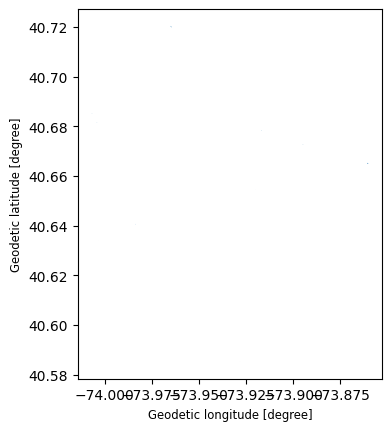

In [41]:
# Get 10 random lots from an existing dataset
ten_vacant_lots = gpd.read_file(
    "/content/drive/MyDrive/ARCH 6131/Example Data/brooklyn_city_vacant_lots.geojson"
).sample(10)
ten_vacant_lots.plot()

In [46]:
def search_for_coffee(row):
    """Gets first place that matches query for coffee from HERE Discover API"""

    # Get the middle point of the lot
    pt = row.geometry.centroid
    latitude = pt.y
    longitude = pt.x

    # Keep under rate limits
    time.sleep(0.1)

    # Set up the request
    params = {
        "at": f"{latitude},{longitude}",
        # Don't forget to enter your API key here!
        "apiKey": HERE_API_KEY,
        "q": "coffee",
    }

    # Make the request and return the first address
    r = requests.get("https://discover.search.hereapi.com/v1/discover?", params=params)
    return r.json()["items"][0]["address"]["label"]

In [47]:
# Apply the function! Cafeful — you'll only have 1,000 free requests with HERE's APIs
ten_vacant_lots["coffee"] = ten_vacant_lots.apply(search_for_coffee, axis=1)

In [ ]:
# That's it!
ten_vacant_lots[["geometry", "coffee"]]

,geometry,coffee
361,"POLYGON ((-73.96612 40.71830, -73.96615 40.718...","Devocion, 69 Grand St, Brooklyn, NY 11249-4110..."
335,"POLYGON ((-73.96991 40.70931, -73.96991 40.709...","Social House Cafe, 60 Broadway, Brooklyn, NY 1..."
227,"POLYGON ((-73.91368 40.67223, -73.91398 40.672...","Dunkin', 1710 Eastern Pkwy, Brooklyn, NY 11233..."
167,"POLYGON ((-73.93937 40.67424, -73.93930 40.674...","Bakerie, 252 Albany Ave, Brooklyn, NY 11213-13..."
727,"POLYGON ((-73.98026 40.58507, -73.98084 40.585...","Dunkin', 2978 Cropsey Ave, Brooklyn, NY 11214-..."
...,...,...
570,"POLYGON ((-73.91479 40.65444, -73.91483 40.654...","Adj Coffee Shop, 1 Brookdale Plz, Brooklyn, NY..."
636,"POLYGON ((-73.96021 40.61839, -73.96022 40.618...","Dunkin', 1510 Elm Ave, Brooklyn, NY 11230, Uni..."
915,"POLYGON ((-73.87770 40.65422, -73.87761 40.654...","Dunkin', 339 Gateway Dr, Brooklyn, NY 11239-28..."
950,"POLYGON ((-73.98483 40.64146, -73.98494 40.641...","Dunkin', 110 Beverley Rd, Brooklyn, NY 11218-3..."
